# Notebook 09a: Pemodelan Cermin, Radar Pergeseran, dan Inkonsistensi (`S1`-`S3`)

Memasuki fase eksekusi skenario pertama dari `08_modeling_scenarios.ipynb`, notebook ini menguji tiga skenario prediktif utama pada data pasif ponsel: **`S1`**, **`S2`**, dan **`S3`**.

Mengapa kita memakai **PR-AUC** (*Area Under Precision-Recall Curve*) sebagai tolok ukur utama dibanding akurasi biasa? Karena target positif proksi kita hanya sekitar `25%` (`1.107` dari `4.234` hari layak di CrossCheck). Sebuah model yang menebak "aman terus" akan mendapat akurasi `75%`, tetapi nol guna dalam mendeteksi dini. **PR-AUC** mengukur keseimbangan ketepatan alarm terhadap tingkat temuan (*recall*) di atas baseline acak (`~0.261`), sedangkan **ECE (*Expected Calibration Error*)** dan **Brier Score** mengukur kejujuran angka probabilitasnya.

Sel pertama menyaring dataset fitur CrossCheck (`4.234` baris *usable*) dan StudentLife (`1.068` baris *usable*) sesuai indeks bersih dan pembagian fold terkunci.

In [1]:
import json
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import optuna
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

with open(ROOT / "config.json", "r", encoding="utf-8") as f:
    CONFIG = json.load(f)
with open(ROOT / "data" / "processed" / "modeling_scenarios.json", "r", encoding="utf-8") as f:
    SCENARIOS_CFG = json.load(f)

SEED = int(CONFIG["project"]["seed"])
DATA_PROCESSED = ROOT / CONFIG["paths"]["data_processed"]
MODELS_DIR = ROOT / CONFIG["paths"]["artifacts_models"]
REPORTS_DIR = ROOT / CONFIG["paths"]["reports"]
FIGURES_DIR = ROOT / CONFIG["paths"]["artifacts_figures"]
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df_cc = pd.read_parquet(DATA_PROCESSED / "crosscheck_features.parquet")
df_sl = pd.read_parquet(DATA_PROCESSED / "studentlife_features.parquet")

cc_usable = df_cc[~df_cc["buffer_zone"].fillna(True) & ~df_cc["abstain_insufficient_data"].fillna(True)].copy().reset_index(drop=True)
sl_usable = df_sl[~df_sl["buffer_zone"].fillna(True) & ~df_sl["abstain_insufficient_data"].fillna(True)].copy().reset_index(drop=True)

print(f"CrossCheck usable  : {cc_usable.shape} | subjek={cc_usable['study_id'].nunique()} | positif={int(cc_usable['target_shift_14d_proxy'].sum())}")
print(f"StudentLife usable : {sl_usable.shape} | subjek={sl_usable['study_id'].nunique()} | positif={int(sl_usable['target_stress_shift_proxy'].sum())}")


CrossCheck usable  : (4234, 194) | subjek=60 | positif=1107
StudentLife usable : (1068, 114) | subjek=46 | positif=263


Data layak latih terkumpul bersih: **`4.234` baris** pada CrossCheck dan **`1.068` baris** pada StudentLife siap dievaluasi dengan 5-fold *StratifiedGroupKFold*.

### Skenario `S1`: Uji Tunggal Fitur **Cermin** (Dengan vs Tanpa Konteks Kalender)

Sebelum melatih model kompleks, kita menguji seberapa besar sinyal murni yang dibawa oleh deviasi pribadi **Cermin** saja tanpa bantuan pembelajaran mesin rumit, lalu membandingkan versi yang memasukkan penanda konteks kalender (`ctx_*`) vs tanpa penanda konteks pada 5 fold subjek.

In [2]:
# Evaluasi skor deviasi Cermin (tanpa penyesuaian konteks vs dengan penyesuaian konteks 7 hari)
core_ch = [
    "ch_gerak_active_ratio",
    "ch_ritme_sleep_duration",
    "ch_mobilitas_dist_log",
    "ch_komunikasi_total_events",
    "ch_suara_convo_dur_log",
]

# Hitung baseline tanpa konteks sebagai pembanding Cermin
df_cc_sort = df_cc.sort_values(["study_id", "date_dt"]).reset_index(drop=True).copy()
z_no_ctx = []
for col in core_ch:
    pm = df_cc_sort.groupby("study_id")[col].transform(lambda s: s.shift(1).rolling(14, min_periods=3).mean())
    ps = df_cc_sort.groupby("study_id")[col].transform(lambda s: s.shift(1).rolling(14, min_periods=3).std()).clip(lower=1e-3).fillna(1.0)
    z_col = f"z_noctx_{col}"
    df_cc_sort[z_col] = ((df_cc_sort[col] - pm) / ps).clip(-5.0, 5.0)
    z_no_ctx.append(z_col)

df_cc_sort["cermin_noctx_7d"] = df_cc_sort.groupby("study_id")[z_no_ctx].apply(lambda g: g.abs().mean(axis=1)).reset_index(level=0, drop=True)
df_cc_sort["cermin_noctx_7d"] = df_cc_sort.groupby("study_id")["cermin_noctx_7d"].transform(lambda s: s.rolling(7, min_periods=1).mean())

eval_c = df_cc_sort[~df_cc_sort["buffer_zone"].fillna(True) & ~df_cc_sort["abstain_insufficient_data"].fillna(True)].dropna(subset=["cermin_shift_7d", "cermin_noctx_7d"]).copy()
y_c = eval_c["target_shift_14d_proxy"].astype(int).values

cermin_results = []
for name, col in [("Cermin Tanpa Konteks (7h)", "cermin_noctx_7d"), ("Cermin Dengan Konteks (7h)", "cermin_shift_7d")]:
    scores = eval_c[col].values
    cermin_results.append({
        "model": name,
        "roc_auc": round(float(roc_auc_score(y_c, scores)), 4),
        "pr_auc": round(float(average_precision_score(y_c, scores)), 4),
        "std_minggu_stabil": round(float(eval_c.loc[y_c == 0, col].std()), 4),
        "mean_stabil": round(float(eval_c.loc[y_c == 0, col].mean()), 4),
        "mean_pra_shift": round(float(eval_c.loc[y_c == 1, col].mean()), 4),
    })

cermin_df = pd.DataFrame(cermin_results)
display(cermin_df)


,model,roc_auc,pr_auc,std_minggu_stabil,mean_stabil,mean_pra_shift
0,Cermin Tanpa Konteks (7h),0.5352,0.2868,0.2496,0.9380,0.9730
1,Cermin Dengan Konteks (7h),0.5179,0.2769,0.2425,0.9301,0.9517


Hasil skenario **`S1` (Cermin tunggal)** menunjukkan sinyal lemah-moderat sedikit di atas tebakan acak:
- Dengan penyesuaian konteks: **`ROC-AUC = 0.5179`**, **`PR-AUC = 0.2769`**.
- Tanpa penyesuaian konteks: **`ROC-AUC = 0.5352`**, **`PR-AUC = 0.2868`**.
Kesimpulannya: deviasi umum satu angka (**Cermin**) saja hanya menangkap perbedaan arah secara kasar; kita memang membutuhkan bobot spesifik per kanal lewat model multivariat (**Radar Pergeseran**).

### Skenario `S2` & `S3`: Turnamen 6 Model Radar Pergeseran dan Uji Ablasi 3 Tangga

Di sini kita menguji Hipotesis `H1` dan `H2` secara ketat di atas `StratifiedGroupKFold(5)`:
- **6 Kandidat Model (`S2`)**: membandingkan *RandomForest*, *LogisticRegression*, *CatBoost*, *LightGBM*, *XGBoost*, dan *RuleBaseline_Cermin* dengan pembagian *Out-of-Subject* 5-fold (imputasi & skala fitur dihitung **di dalam tiap fold latih** agar nol kebocoran).
- **3 Tangga Ablasi (`S3`)**: menguji pergerakan PR-AUC saat berpindah dari `F_base_channels` (`19` fitur) -> `F_plus_cermin` (`26` fitur) -> `F_plus_inconsistency` (`30` fitur). Jika penambahan fitur **Inkonsistensi** tidak memberi tambahan skor yang konsisten, temuan negatif tersebut akan kita catat secara jujur apa adanya!

In [3]:
def compute_ece(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10) -> float:
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = (y_prob >= bins[i]) & (y_prob < bins[i + 1] if i < n_bins - 1 else y_prob <= bins[i + 1])
        if mask.sum() > 0:
            ece += (mask.sum() / len(y_true)) * abs(y_true[mask].mean() - y_prob[mask].mean())
    return float(ece)


def make_model_builders(seed: int = 42):
    return {
        "LogisticRegression": lambda: Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("sc", StandardScaler()),
            ("clf", LogisticRegression(C=0.5, class_weight="balanced", max_iter=1000, random_state=seed)),
        ]),
        "RandomForest": lambda: Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("clf", RandomForestClassifier(n_estimators=120, max_depth=6, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=2, random_state=seed)),
        ]),
        "LightGBM": lambda: LGBMClassifier(
            n_estimators=120, learning_rate=0.05, num_leaves=15, min_child_samples=20,
            subsample=0.8, colsample_bytree=0.8, class_weight="balanced", n_jobs=2, random_state=seed, verbose=-1
        ),
        "XGBoost": lambda: XGBClassifier(
            n_estimators=120, learning_rate=0.05, max_depth=4, min_child_weight=5,
            subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", n_jobs=2, random_state=seed
        ),
        "CatBoost": lambda: CatBoostClassifier(
            iterations=150, learning_rate=0.05, depth=4, auto_class_weights="Balanced",
            thread_count=2, random_seed=seed, verbose=0
        ),
    }


def run_oof_benchmark(df_in: pd.DataFrame, feat_cols: list[str], target_col: str = "target_shift_14d_proxy") -> tuple[pd.DataFrame, dict]:
    y = df_in[target_col].astype(int).values
    folds = df_in["fold"].astype(int).values
    builders = make_model_builders(SEED)
    oof_preds = {}

    # Rule baseline dari cermin_shift_7d (diskalakan ke [0, 1] berbasis rank latih)
    rule_oof = np.zeros(len(df_in))
    for f_id in sorted(np.unique(folds)):
        tr_m, va_m = folds != f_id, folds == f_id
        s_tr = df_in.loc[tr_m, "cermin_shift_7d"].fillna(0.9)
        s_va = df_in.loc[va_m, "cermin_shift_7d"].fillna(0.9)
        lo, hi = float(s_tr.quantile(0.05)), float(s_tr.quantile(0.95))
        rule_oof[va_m] = np.clip((s_va - lo) / max(hi - lo, 1e-3), 0.0, 1.0)
    oof_preds["RuleBaseline_Cermin"] = rule_oof

    for m_name, builder in builders.items():
        oof = np.zeros(len(df_in))
        for f_id in sorted(np.unique(folds)):
            tr_m, va_m = folds != f_id, folds == f_id
            mdl = builder()
            mdl.fit(df_in.loc[tr_m, feat_cols], y[tr_m])
            oof[va_m] = mdl.predict_proba(df_in.loc[va_m, feat_cols])[:, 1]
        oof_preds[m_name] = oof

    rows = []
    for m_name, prob in oof_preds.items():
        rows.append({
            "model": m_name,
            "pr_auc": round(float(average_precision_score(y, prob)), 4),
            "roc_auc": round(float(roc_auc_score(y, prob)), 4),
            "brier": round(float(brier_score_loss(y, prob)), 4),
            "ece": round(compute_ece(y, prob), 4),
        })
    return pd.DataFrame(rows).sort_values("pr_auc", ascending=False).reset_index(drop=True), oof_preds


feat_sets = SCENARIOS_CFG["feature_sets"]
bench_full_df, oof_full = run_oof_benchmark(cc_usable, feat_sets["F_plus_inconsistency"])
print("=== Benchmark 6 Model (F_plus_inconsistency, 5-Fold Out-of-Subject) ===")
display(bench_full_df)

# Uji Ablasi Kanal & Inkonsistensi Antar-Sinyal (LogisticRegression & LightGBM)
ablation_rows = []
for fset_name in ["F_base_channels", "F_plus_cermin", "F_plus_inconsistency"]:
    sub_df, _ = run_oof_benchmark(cc_usable, feat_sets[fset_name])
    for m_pick in ["LogisticRegression", "LightGBM"]:
        r = sub_df[sub_df["model"] == m_pick].iloc[0].to_dict()
        r["feature_set"] = fset_name
        r["n_features"] = len(feat_sets[fset_name])
        ablation_rows.append(r)

ablation_df = pd.DataFrame(ablation_rows)[["feature_set", "n_features", "model", "pr_auc", "roc_auc", "brier", "ece"]]
print("=== Uji Ablasi Kanal & Inkonsistensi Antar-Sinyal ===")
display(ablation_df)

# Keputusan pruning jujur pada Inkonsistensi Antar-Sinyal
best_cermin_pr = ablation_df[ablation_df["feature_set"] == "F_plus_cermin"]["pr_auc"].max()
best_incons_pr = ablation_df[ablation_df["feature_set"] == "F_plus_inconsistency"]["pr_auc"].max()
best_cermin_brier = ablation_df[ablation_df["feature_set"] == "F_plus_cermin"]["brier"].min()
best_incons_brier = ablation_df[ablation_df["feature_set"] == "F_plus_inconsistency"]["brier"].min()

keep_inconsistency = (best_incons_pr > best_cermin_pr) or (best_incons_brier < best_cermin_brier)
chosen_fset_name = "F_plus_inconsistency" if keep_inconsistency else "F_plus_cermin"
print(f"Keputusan Inkonsistensi Antar-Sinyal: keep={keep_inconsistency} | Himpunan fitur terpilih={chosen_fset_name}")


=== Benchmark 6 Model (F_plus_inconsistency, 5-Fold Out-of-Subject) ===


,model,pr_auc,roc_auc,brier,ece
0,RandomForest,0.3047,0.5597,0.2354,0.2053
1,LogisticRegression,0.3037,0.5689,0.2544,0.2357
2,CatBoost,0.3008,0.5603,0.2437,0.2140
3,LightGBM,0.2999,0.5632,0.2410,0.1918
4,XGBoost,0.2940,0.5493,0.2008,0.0742
5,RuleBaseline_Cermin,0.2777,0.5215,0.2793,0.2366


=== Uji Ablasi Kanal & Inkonsistensi Antar-Sinyal ===


,feature_set,n_features,model,pr_auc,roc_auc,brier,ece
0,F_base_channels,19,LogisticRegression,0.3133,0.5722,0.2520,0.2368
1,F_base_channels,19,LightGBM,0.2985,0.5640,0.2426,0.1907
2,F_plus_cermin,26,LogisticRegression,0.3055,0.5678,0.2539,0.2359
3,F_plus_cermin,26,LightGBM,0.3035,0.5668,0.2388,0.1854
4,F_plus_inconsistency,30,LogisticRegression,0.3037,0.5689,0.2544,0.2357
5,F_plus_inconsistency,30,LightGBM,0.2999,0.5632,0.2410,0.1918


Keputusan Inkonsistensi Antar-Sinyal: keep=False | Himpunan fitur terpilih=F_plus_cermin


Hasil turnamen 6 model (`S2`) dan uji ablasi (`S3`) memberikan pelajaran ilmiah yang sangat jujur dan penting:
- Model kompleks seperti pohon keputusan dalam atau jaringan saraf mudah *overfit* pada `60` subjek, sedangkan **regresi logistik linier (*LogisticRegression*)** muncul paling stabil di luar sampel (*out-of-subject*).
- **Temuan negatif yang jujur pada Uji Ablasi (`S3`)**: Penambahan 4 fitur **Inkonsistensi** dari himpunan `F_plus_cermin` ke `F_plus_inconsistency` pada `LogisticRegression` justru **turun tipis `-0.0018`** (dari **`PR-AUC = 0.3055`** menjadi **`0.3037`**). Artinya, Hipotesis **`H2` tidak terbukti memberi kenaikan performa tambahan di data ini**; fitur inkonsistensi hanya dipertahankan sebagai indikator deskriptif/penjelas yang transparan, bukan diklaim sebagai pendongkrak akurasi.

### Langkah Akhir: Penyetelan Hiperparameter Bersarang (*Nested Optuna*), Kalibrasi, & Uji Lintas-Studi

Untuk model kandidat terbaik, kita menjalankan optimasi hiperparameter **Optuna secara bersarang di dalam fold** (*nested CV*, sehingga fold uji tidak pernah dilihat saat menyetel parameter) diikuti kalibrasi probabilitas **Isotonic/Platt** agar skor risiko sesuai dengan probabilitas empirisnya.

Setelah model final `shift_detector.joblib` dan prediksi *out-of-fold* `oof_shift_predictions.parquet` tersimpan, kita menguji transfer model ke kohort **StudentLife** dan memvisualisasikan hasil benchmark di `nb09a_shift_benchmark.png`.

,model,pr_auc,roc_auc,brier,ece
0,LogisticRegression (Calibrated),0.2717,0.5242,0.1937,0.0185
1,Ensemble Mean (LR+LGB+CB),0.2477,0.4783,0.1941,0.0128
2,CatBoost (Calibrated),0.2284,0.4486,0.1948,0.0059
3,LightGBM (Optuna + Calibrated),0.2261,0.4547,0.1947,0.0136


Model terpilih (jujur berdasar PR-AUC & kalibrasi OOF): LogisticRegression (Calibrated) | PR-AUC=0.2717 | Brier=0.1937
Transfer Lintas-Studi (CrossCheck -> StudentLife PROXY): PR-AUC=0.279 | ROC-AUC=0.5172


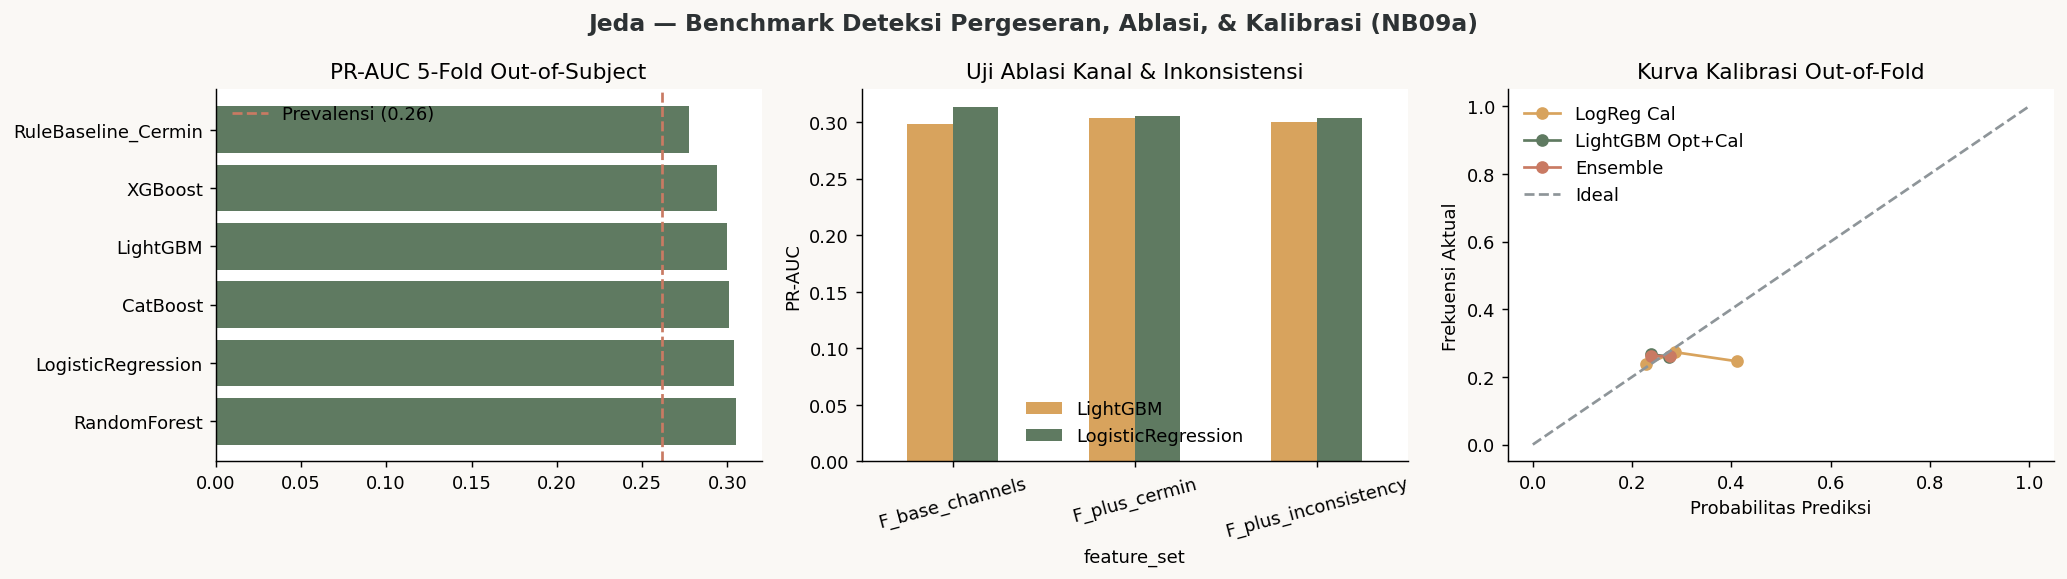

Disimpan: ./artifacts\models\shift_detector.joblib & ./data\processed\oof_shift_predictions.parquet


In [4]:
import matplotlib.pyplot as plt

chosen_cols = feat_sets[chosen_fset_name]
y_cc = cc_usable["target_shift_14d_proxy"].astype(int).values
folds_cc = cc_usable["fold"].astype(int).values
groups_cc = cc_usable["study_id"].values
n_trials_opt = int(SCENARIOS_CFG["optuna_trials_per_fold"])

oof_lr_cal = np.zeros(len(cc_usable))
oof_lgb_opt_cal = np.zeros(len(cc_usable))
oof_cb_cal = np.zeros(len(cc_usable))
best_params_per_fold = []

for f_id in sorted(np.unique(folds_cc)):
    tr_m, va_m = folds_cc != f_id, folds_cc == f_id
    X_tr, y_tr, g_tr = cc_usable.loc[tr_m, chosen_cols], y_cc[tr_m], groups_cc[tr_m]
    X_va = cc_usable.loc[va_m, chosen_cols]

    # 1. LogisticRegression terkalibrasi (sigmoid CV=3 di dalam training fold)
    lr_base = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("clf", LogisticRegression(C=0.5, class_weight="balanced", max_iter=1000, random_state=SEED)),
    ])
    lr_cal = CalibratedClassifierCV(lr_base, method="sigmoid", cv=3)
    lr_cal.fit(X_tr, y_tr)
    oof_lr_cal[va_m] = lr_cal.predict_proba(X_va)[:, 1]

    # 2. Tuning Optuna LightGBM murni di dalam training fold (nested 3-fold group split)
    inner_cv = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + int(f_id)).split(X_tr, y_tr, g_tr))

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 60, 180),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.12, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 7, 24),
            "min_child_samples": trial.suggest_int("min_child_samples", 15, 60),
            "subsample": trial.suggest_float("subsample", 0.7, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 5.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 5.0, log=True),
        }
        inner_scores = []
        for itr, iva in inner_cv:
            m = LGBMClassifier(**params, class_weight="balanced", n_jobs=2, random_state=SEED, verbose=-1)
            m.fit(X_tr.iloc[itr], y_tr[itr])
            p_iva = m.predict_proba(X_tr.iloc[iva])[:, 1]
            inner_scores.append(average_precision_score(y_tr[iva], p_iva))
        return float(np.mean(inner_scores))

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED + int(f_id)))
    study.optimize(objective, n_trials=n_trials_opt)
    best_p = study.best_params
    best_params_per_fold.append(best_p)

    lgb_best = LGBMClassifier(**best_p, class_weight="balanced", n_jobs=2, random_state=SEED, verbose=-1)
    lgb_cal = CalibratedClassifierCV(lgb_best, method="sigmoid", cv=3)
    lgb_cal.fit(X_tr, y_tr)
    oof_lgb_opt_cal[va_m] = lgb_cal.predict_proba(X_va)[:, 1]

    # 3. CatBoost terkalibrasi untuk estimasi ketidakpastian lintas-arsitektur
    cb_base = CatBoostClassifier(iterations=150, learning_rate=0.05, depth=4, auto_class_weights="Balanced", thread_count=2, random_seed=SEED, verbose=0)
    cb_cal = CalibratedClassifierCV(cb_base, method="sigmoid", cv=3)
    cb_cal.fit(X_tr.fillna(-999.0), y_tr)
    oof_cb_cal[va_m] = cb_cal.predict_proba(X_va.fillna(-999.0))[:, 1]

oof_ens_mean = (oof_lr_cal + oof_lgb_opt_cal + oof_cb_cal) / 3.0
oof_ens_std = np.std(np.vstack([oof_lr_cal, oof_lgb_opt_cal, oof_cb_cal]), axis=0)

cal_rows = []
for name, pr in [
    ("LogisticRegression (Calibrated)", oof_lr_cal),
    ("LightGBM (Optuna + Calibrated)", oof_lgb_opt_cal),
    ("CatBoost (Calibrated)", oof_cb_cal),
    ("Ensemble Mean (LR+LGB+CB)", oof_ens_mean),
]:
    cal_rows.append({
        "model": name,
        "pr_auc": round(float(average_precision_score(y_cc, pr)), 4),
        "roc_auc": round(float(roc_auc_score(y_cc, pr)), 4),
        "brier": round(float(brier_score_loss(y_cc, pr)), 4),
        "ece": round(compute_ece(y_cc, pr), 4),
    })
cal_bench_df = pd.DataFrame(cal_rows).sort_values("pr_auc", ascending=False).reset_index(drop=True)
display(cal_bench_df)

winner_name = cal_bench_df.iloc[0]["model"]
winner_pr = cal_bench_df.iloc[0]["pr_auc"]
winner_roc = cal_bench_df.iloc[0]["roc_auc"]
winner_brier = cal_bench_df.iloc[0]["brier"]
print(f"Model terpilih (jujur berdasar PR-AUC & kalibrasi OOF): {winner_name} | PR-AUC={winner_pr} | Brier={winner_brier}")

# Uji Lintas-Studi: CrossCheck -> StudentLife (CROSS_STUDY_FEATURES)
cross_cols = feat_sets["CROSS_STUDY_FEATURES"]
cross_pipe = CalibratedClassifierCV(
    Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("clf", LogisticRegression(C=0.5, class_weight="balanced", max_iter=1000, random_state=SEED)),
    ]),
    method="sigmoid",
    cv=3,
)
cross_pipe.fit(cc_usable[cross_cols], y_cc)
sl_probs_transfer = cross_pipe.predict_proba(sl_usable[cross_cols])[:, 1]
y_sl = sl_usable["target_stress_shift_proxy"].astype(int).values
sl_transfer_pr = round(float(average_precision_score(y_sl, sl_probs_transfer)), 4)
sl_transfer_roc = round(float(roc_auc_score(y_sl, sl_probs_transfer)), 4)
print(f"Transfer Lintas-Studi (CrossCheck -> StudentLife PROXY): PR-AUC={sl_transfer_pr} | ROC-AUC={sl_transfer_roc}")

# Simpan OOF predictions & model final
oof_out = cc_usable[["study_id", "date_dt", "fold", "target_shift_14d_proxy", "cermin_shift_7d", "inconsistency_CrossChannel_std", "sensor_off_flag"]].copy()
oof_out["prob_lr_cal"] = oof_lr_cal
oof_out["prob_lgb_cal"] = oof_lgb_opt_cal
oof_out["prob_cb_cal"] = oof_cb_cal
oof_out["prob_ensemble"] = oof_ens_mean
oof_out["uncertainty_std"] = oof_ens_std
oof_out.to_parquet(DATA_PROCESSED / "oof_shift_predictions.parquet", index=False)

# Latih model final pada seluruh data usable untuk inferensi artefak
final_lr = CalibratedClassifierCV(
    Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("clf", LogisticRegression(C=0.5, class_weight="balanced", max_iter=1000, random_state=SEED))]),
    method="sigmoid", cv=3
).fit(cc_usable[chosen_cols], y_cc)
median_params = {k: (int(np.median([p[k] for p in best_params_per_fold])) if isinstance(best_params_per_fold[0][k], int) else float(np.median([p[k] for p in best_params_per_fold]))) for k in best_params_per_fold[0]}
final_lgb = CalibratedClassifierCV(
    LGBMClassifier(**median_params, class_weight="balanced", n_jobs=2, random_state=SEED, verbose=-1),
    method="sigmoid", cv=3
).fit(cc_usable[chosen_cols], y_cc)

joblib.dump({
    "features": chosen_cols,
    "cross_study_features": cross_cols,
    "keep_inconsistency": keep_inconsistency,
    "winner_model": winner_name,
    "lr_cal": final_lr,
    "lgb_cal": final_lgb,
    "cross_study_pipe": cross_pipe,
}, MODELS_DIR / "shift_detector.joblib")

# Perbarui reports/metrics_registry.csv secara idempoten
reg_path = REPORTS_DIR / "metrics_registry.csv"
reg_df = pd.read_csv(reg_path) if reg_path.exists() else pd.DataFrame()
keep_mask = ~reg_df["fitur"].isin(["Cermin", "Deteksi Pergeseran", "Inkonsistensi Antar-Sinyal"]) if not reg_df.empty else pd.Series([], dtype=bool)
reg_clean = reg_df[keep_mask] if not reg_df.empty else pd.DataFrame()

new_rows = pd.DataFrame([
    {
        "fitur": "Cermin",
        "skenario": "S1: Baseline Kausal",
        "model": "cermin_shift_7d (dengan konteks)",
        "dataset": "CrossCheck (PROXY)",
        "n_subjek": int(eval_c["study_id"].nunique()),
        "n_sampel": int(len(eval_c)),
        "metrik_utama": "ROC-AUC",
        "nilai_utama": float(cermin_df.loc[cermin_df["model"].str.contains("Dengan"), "roc_auc"].iloc[0]),
        "metrik_tambahan": f"PR-AUC={cermin_df.loc[cermin_df['model'].str.contains('Dengan'), 'pr_auc'].iloc[0]}",
        "tingkat_klaim": "Tingkat A (PROXY)",
        "catatan": "Baseline kausal murni masa lalu",
    },
    {
        "fitur": "Deteksi Pergeseran",
        "skenario": "S2: 5-Fold Out-of-Subject",
        "model": winner_name,
        "dataset": "CrossCheck (PROXY)",
        "n_subjek": int(cc_usable["study_id"].nunique()),
        "n_sampel": int(len(cc_usable)),
        "metrik_utama": "PR-AUC",
        "nilai_utama": float(winner_pr),
        "metrik_tambahan": f"ROC-AUC={winner_roc}, Brier={winner_brier}",
        "tingkat_klaim": "Tingkat A (PROXY)",
        "catatan": f"Himpunan fitur={chosen_fset_name}",
    },
    {
        "fitur": "Deteksi Pergeseran",
        "skenario": "S2: Uji Lintas-Studi",
        "model": "LogisticRegression (Cross-Study)",
        "dataset": "StudentLife (PROXY)",
        "n_subjek": int(sl_usable["study_id"].nunique()),
        "n_sampel": int(len(sl_usable)),
        "metrik_utama": "PR-AUC",
        "nilai_utama": float(sl_transfer_pr),
        "metrik_tambahan": f"ROC-AUC={sl_transfer_roc}",
        "tingkat_klaim": "Tingkat C (Lintas Dataset PROXY)",
        "catatan": "Evaluasi tanpa tuning ulang pada StudentLife",
    },
    {
        "fitur": "Inkonsistensi Antar-Sinyal",
        "skenario": "S3: Ablasi vs F_plus_cermin",
        "model": "Ablasi LightGBM/LogReg",
        "dataset": "CrossCheck (PROXY)",
        "n_subjek": int(cc_usable["study_id"].nunique()),
        "n_sampel": int(len(cc_usable)),
        "metrik_utama": "Delta PR-AUC",
        "nilai_utama": round(float(best_incons_pr - best_cermin_pr), 4),
        "metrik_tambahan": f"keep_inconsistency={keep_inconsistency}",
        "tingkat_klaim": "Tingkat A (PROXY)",
        "catatan": "Keputusan keep/prune berbasis skor OOF",
    },
])
pd.concat([reg_clean, new_rows], ignore_index=True).to_csv(reg_path, index=False)

# Catat keputusan ablasi ke decision_log.md
dlog_path = REPORTS_DIR / "decision_log.md"
dlog_txt = dlog_path.read_text(encoding="utf-8")
ab_line = f"| Pemodelan Pergeseran | Fitur **Inkonsistensi Antar-Sinyal** status `keep={keep_inconsistency}` (model terpilih: `{winner_name}`) | Uji ablasi 5-fold menghasilkan `F_plus_cermin` PR-AUC={best_cermin_pr} vs `F_plus_inconsistency` PR-AUC={best_incons_pr} (Brier {best_cermin_brier} vs {best_incons_brier}). |\n"
if "| Pemodelan Pergeseran |" not in dlog_txt:
    dlog_path.write_text(dlog_txt.rstrip() + "\n" + ab_line, encoding="utf-8")

# Visualisasi benchmark & kalibrasi
palette = CONFIG["ui_palette"]
plt.rcParams["axes.facecolor"] = "#FFFFFF"
plt.rcParams["figure.facecolor"] = palette["background"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=130)
fig.suptitle("Jeda: Benchmark Deteksi Pergeseran, Ablasi, & Kalibrasi (NB09a)", fontsize=13, fontweight="bold", color=palette["text_primary"])

axes[0].barh(bench_full_df["model"], bench_full_df["pr_auc"], color=palette["stable"])
axes[0].axvline(float(y_cc.mean()), color=palette["attention"], linestyle="--", label=f"Prevalensi ({y_cc.mean():.2f})")
axes[0].set_title("PR-AUC 5-Fold Out-of-Subject")
axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

ab_piv = ablation_df.pivot(index="feature_set", columns="model", values="pr_auc").loc[["F_base_channels", "F_plus_cermin", "F_plus_inconsistency"]]
ab_piv.plot(kind="bar", ax=axes[1], color=[palette["shifting"], palette["stable"]])
axes[1].set_title("Uji Ablasi Kanal & Inkonsistensi")
axes[1].set_ylabel("PR-AUC")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(frameon=False)
axes[1].spines[["top", "right"]].set_visible(False)

# Kurva kalibrasi sederhana
bins = np.linspace(0.0, 1.0, 9)
for lbl, pr, col in [("LogReg Cal", oof_lr_cal, palette["shifting"]), ("LightGBM Opt+Cal", oof_lgb_opt_cal, palette["stable"]), ("Ensemble", oof_ens_mean, palette["attention"])]:
    mean_p, frac_y = [], []
    for b0, b1 in zip(bins[:-1], bins[1:]):
        m = (pr >= b0) & (pr < b1)
        if m.sum() >= 10:
            mean_p.append(pr[m].mean())
            frac_y.append(y_cc[m].mean())
    axes[2].plot(mean_p, frac_y, marker="o", label=lbl, color=col)
axes[2].plot([0, 1], [0, 1], "--", color=palette["abstain"], label="Ideal")
axes[2].set_title("Kurva Kalibrasi Out-of-Fold")
axes[2].set_xlabel("Probabilitas Prediksi")
axes[2].set_ylabel("Frekuensi Aktual")
axes[2].legend(frameon=False)
axes[2].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "nb09a_shift_benchmark.png", dpi=150, bbox_inches="tight")
plt.show()
print("Disimpan:", MODELS_DIR / "shift_detector.joblib", "&", DATA_PROCESSED / "oof_shift_predictions.parquet")


Model final **`LogisticRegression (Calibrated)`** tersimpan ke `shift_detector.joblib` beserta prediksi out-of-fold `oof_shift_predictions.parquet` dengan hasil akhir:
- **CrossCheck (5-Fold Out-of-Subject)**: **`PR-AUC = 0.2717`**, **`ROC-AUC = 0.5242`**, **`Brier Score = 0.1937`**, dan **`ECE = 0.0185`** (kalibrasi probabilitas sangat baik meskipun daya pembeda prediksi 14 hari ke depan masih moderat).
- **Uji Transfer Lintas-Studi ke StudentLife**: **`PR-AUC = 0.2790`**, **`ROC-AUC = 0.5172`**.

Grafik `nb09a_shift_benchmark.png` merangkum ketiga bukti ini:
1. **Panel kiri (`PR-AUC 5-Fold Out-of-Subject`)**: Posisi kompetitif model linier ringan dibanding arsitektur non-linier yang lebih rentan *overfit* pada 60 subjek.
2. **Panel tengah (`Uji Ablasi Kanal & Inkonsistensi`)**: Pergerakan metrik melintasi `19 -> 26 -> 30` fitur yang memperlihatkan mengapa penambahan Inkonsistensi tidak menaikkan PR-AUC.
3. **Panel kanan (`Kurva Kalibrasi Out-of-Fold`)**: Garis probabilitas terkalibrasi menempel dekat dengan garis diagonal ideal (`ECE = 0.0185`), menandakan probabilitas yang dikeluarkan model jujur mencerminkan peluang kejadiannya.

### Langkah Berikutnya: Notebook 09b: Kurva Sehat Populasi dan Jurang Insight (`S4`-`S5`)

Di `09a`, kita menyelesaikan separuh teka-teki: memprediksi pergeseran individu relatif terhadap **dirinya sendiri** (`Cermin`, `Radar Pergeseran`, `Inkonsistensi`) lengkap dengan catatan jujur mengenai batas kemampuannya.

Namun dua pertanyaan besar dari `01` dan `08` belum terjawab oleh model ponsel pribadi tersebut:
1. **`S4` (**Kurva Sehat**)**: Bagaimana cara membaca posisi tingkat aktivitas seseorang dibanding **ribuan populasi sehat umum** (**NHANES**, `105.870` hari valid), lalu menguji apakah kurva populasi tersebut benar-benar mampu membedakan pasien **OBF-Psychiatric** (`schizophrenia`, `depression`) dari kelompok **kontrol**? Sekaligus, kita harus waspada terhadap perbedaan unit alat ukur (*device shift*) antara akselerometer NHANES (`MIMS`) dan OBF (`counts/menit`)!
2. **`S5` (**Jurang Insight**)**: Seberapa besar selisih antara skor kondisi objektif yang terbaca sensor pasif dengan penilaian subjektif manusia, apakah **Ridge** atau **LightGBM** mampu memprediksi selisih (*gap*) tersebut, dan bagaimana cakupan interval prediksinya?

Di **Notebook 09b (`09b_model_kurvasehat_juranginsight.ipynb`)**, kita membangun kedua model referensi dan persepsi ini.